Libraries imported successfully!

Dataset created successfully!


,application_date,income,loan_amount,credit_score,employment_type,education_level,city,loan_default
0,2024-01-01,141958,475309,338,Self-employed,Master,Coimbatore,1
1,2024-01-02,35795,261810,572,Self-employed,Bachelor,Bangalore,1
2,2024-01-03,20860,482950,530,Business,Master,Chennai,1
3,2024-01-04,123694,253687,385,Salaried,Diploma,Chennai,1
4,2024-01-05,148106,123523,773,Business,Diploma,Erode,0



Missing values:
application_date     0
income              30
loan_amount          0
credit_score        25
employment_type     20
education_level     15
city                10
loan_default         0
dtype: int64

Training shape: (480, 7)
Validation shape: (120, 7)

Logistic Regression Validation Accuracy:
0.8917

Logistic Regression Predict Probabilities:
[[0.72333747 0.27666253]
 [0.28508296 0.71491704]
 [0.35986953 0.64013047]
 [0.31626863 0.68373137]
 [0.87884545 0.12115455]]

Predicted Classes:
[0 1 1 1 0]

Actual Classes:
[0 1 1 1 0]

Decision Tree Validation Accuracy:
0.8167

Random Forest Validation Accuracy:
0.825

Random Forest OOB Score:
0.8104

XGBoost Validation Accuracy:
0.85

XGBoost Best Iteration:
101

CLASSIFICATION RESULTS:


,Model,Validation Score
0,Logistic Regression,0.891667
1,Decision Tree,0.816667
2,Random Forest,0.825000
3,XGBoost,0.850000



TOP 5 RANDOM FOREST FEATURES:


,Feature,Importance
4,numeric__income_loan_ratio,0.246755
2,numeric__credit_score,0.187161
0,numeric__income,0.168274
5,numeric__log_loan_amount,0.136430
1,numeric__loan_amount,0.132299


... (3 outputs left out)

,Model,Intercept,Coefficient Count,Zero Coefficients
0,Linear Regression,278016.744695,10,0
1,Ridge,278012.076107,10,0
2,Lasso,278073.903173,10,4



REGRESSION COEFFICIENT COMPARISON:


,Linear Regression,Ridge,Lasso
0,-5689.717380,-5679.864683,-4639.645014
1,8487.979714,8473.534011,7467.314394
2,6472.660859,6438.155138,1890.715963
3,-7774.544155,-7734.973103,-6094.651890
4,1301.883296,1296.817964,0.000000
5,-1515.873308,-1504.377545,-0.000000
6,5486.253481,5451.432583,2224.584332
7,-2326.410711,-2313.651841,-0.000000
8,-1643.969462,-1633.403197,-0.000000
9,-4001.110478,-3998.513193,-3585.292844



LASSO ZERO COEFFICIENT COUNT:
4


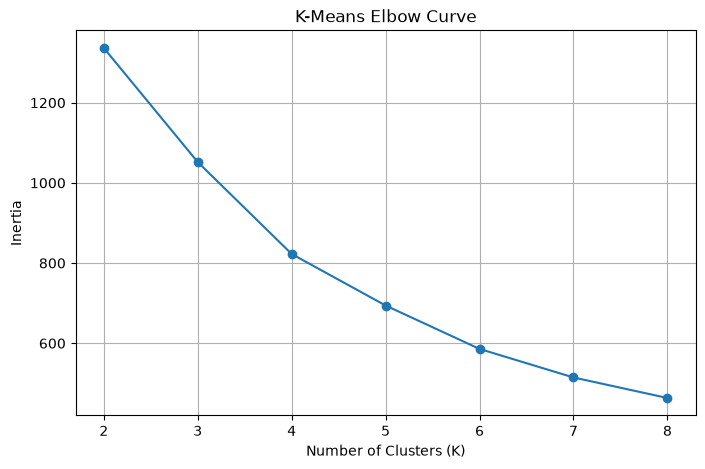


SILHOUETTE SCORES:


,K,Silhouette Score
0,2,0.247918
1,3,0.252454
2,4,0.279070
3,5,0.278873
4,6,0.290738
5,7,0.288715
6,8,0.282679


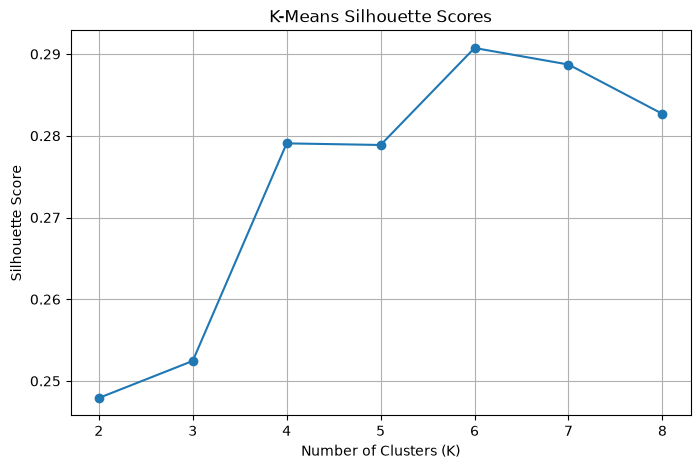


BEST K VALUE:
6

CLUSTER SEGMENT SUMMARY:


,income,credit_score,loan_amount
Cluster,,,
0,107339.26,708.20,143284.50
1,55927.91,443.77,387418.98
2,121825.11,630.75,403385.61
3,122627.22,404.39,215762.60
4,47142.77,499.53,147991.45
5,57192.14,740.38,353877.16



WEEK 2 ASSESSMENT - TASK 3 COMPLETED
1. Logistic Regression - Completed
2. Decision Tree - Completed
3. Random Forest with OOB Score - Completed
4. XGBoost with Early Stopping - Completed
5. Predict Probabilities - Completed
6. Top 5 Feature Importances - Completed
7. Linear Regression - Completed
8. Ridge Regression - Completed
9. Lasso Regression - Completed
10. K-Means Clustering - Completed
11. Elbow Curve - Completed
12. Silhouette Scores - Completed
13. Cluster Segmentation - Completed


In [1]:
# ============================================================
# WEEK 2 ASSESSMENT - TASK 3
# MODELS: SUPERVISED AND UNSUPERVISED
# ============================================================


# 1. IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import xgboost as xgb

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import (
    LogisticRegression,
    LinearRegression,
    Ridge,
    Lasso
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score,
    silhouette_score
)

from pathlib import Path

print("Libraries imported successfully!")


# ============================================================
# 2. CREATE SYNTHETIC LOAN DATASET
# ============================================================

np.random.seed(42)

n = 600

df = pd.DataFrame({

    "application_date": pd.date_range(
        start="2024-01-01",
        periods=n,
        freq="D"
    ).astype(str),

    "income": np.random.randint(20000, 150000, n),

    "loan_amount": np.random.randint(50000, 500000, n),

    "credit_score": np.random.randint(300, 850, n),

    "employment_type": np.random.choice(
        ["Salaried", "Self-employed", "Business"], n
    ),

    "education_level": np.random.choice(
        ["High School", "Diploma", "Bachelor", "Master", "PhD"], n
    ),

    "city": np.random.choice(
        ["Chennai", "Coimbatore", "Bangalore", "Erode"], n
    )
})

risk_score = (
    -2.0 * (df["income"] / df["loan_amount"])
    - 0.002 * (df["credit_score"] - 300)
    + np.random.normal(0, 0.25, n)
)

threshold = np.quantile(risk_score, 0.55)

df["loan_default"] = (risk_score > threshold).astype(int)

print("\nDataset created successfully!")

display(df.head())


# Introduce missing values

for column, count in [
    ("income", 30),
    ("credit_score", 25),
    ("employment_type", 20),
    ("education_level", 15),
    ("city", 10)
]:

    indices = np.random.choice(df.index, count, replace=False)

    df.loc[indices, column] = np.nan


print("\nMissing values:")

print(df.isnull().sum())


# ============================================================
# 3. FEATURE ENGINEERING
# ============================================================

class LoanFeatureEngineer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):

        X = X.copy()

        dates = pd.to_datetime(
            X["application_date"],
            errors="coerce"
        )

        X["application_month"] = dates.dt.month

        X["income_loan_ratio"] = (
            X["income"] /
            X["loan_amount"].replace(0, np.nan)
        )

        X["log_loan_amount"] = np.log1p(
            X["loan_amount"].clip(lower=0)
        )

        X = X.drop(columns=["application_date"])

        return X


# ============================================================
# 4. TRAIN AND VALIDATION SPLIT
# ============================================================

X = df.drop("loan_default", axis=1)

y = df["loan_default"]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining shape:", X_train.shape)

print("Validation shape:", X_val.shape)


# ============================================================
# 5. CREATE PREPROCESSING PIPELINE
# ============================================================

numeric_features = [
    "income",
    "loan_amount",
    "credit_score",
    "application_month",
    "income_loan_ratio",
    "log_loan_amount"
]

categorical_features = [
    "employment_type",
    "city"
]

ordinal_features = [
    "education_level"
]


numeric_pipeline = Pipeline([

    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler())

])


categorical_pipeline = Pipeline([

    ("imputer", SimpleImputer(strategy="most_frequent")),

    ("encoder", OneHotEncoder(handle_unknown="ignore"))

])


ordinal_pipeline = Pipeline([

    ("imputer", SimpleImputer(strategy="most_frequent")),

    ("encoder", OrdinalEncoder(
        categories=[[
            "High School",
            "Diploma",
            "Bachelor",
            "Master",
            "PhD"
        ]],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))

])


preprocessor = ColumnTransformer([

    ("numeric", numeric_pipeline, numeric_features),

    ("categorical", categorical_pipeline, categorical_features),

    ("ordinal", ordinal_pipeline, ordinal_features)

])


# ============================================================
# 6. PREPARE DATA FOR XGBOOST EARLY STOPPING
# ============================================================

feature_pipeline = Pipeline([

    ("feature_engineering", LoanFeatureEngineer()),

    ("preprocessor", preprocessor)

])

X_train_processed = feature_pipeline.fit_transform(X_train, y_train)

X_val_processed = feature_pipeline.transform(X_val)

feature_names = feature_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()


# ============================================================
# 7. LOGISTIC REGRESSION
# ============================================================

logistic_model = Pipeline([

    ("feature_engineering", LoanFeatureEngineer()),

    ("preprocessor", preprocessor),

    ("model", LogisticRegression(max_iter=2000))

])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_val)

logistic_score = accuracy_score(
    y_val,
    logistic_predictions
)

print("\nLogistic Regression Validation Accuracy:")

print(round(logistic_score, 4))


# Predict probabilities for 5 rows

probabilities = logistic_model.predict_proba(
    X_val.iloc[:5]
)

predictions = logistic_model.predict(
    X_val.iloc[:5]
)

print("\nLogistic Regression Predict Probabilities:")

print(probabilities)

print("\nPredicted Classes:")

print(predictions)

print("\nActual Classes:")

print(y_val.iloc[:5].values)


# ============================================================
# 8. DECISION TREE CLASSIFIER
# ============================================================

decision_tree_model = Pipeline([

    ("feature_engineering", LoanFeatureEngineer()),

    ("preprocessor", preprocessor),

    ("model", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))

])

decision_tree_model.fit(X_train, y_train)

dt_predictions = decision_tree_model.predict(X_val)

dt_score = accuracy_score(y_val, dt_predictions)

print("\nDecision Tree Validation Accuracy:")

print(round(dt_score, 4))


# ============================================================
# 9. RANDOM FOREST CLASSIFIER WITH OOB SCORE
# ============================================================

forest_model = Pipeline([

    ("feature_engineering", LoanFeatureEngineer()),

    ("preprocessor", preprocessor),

    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        bootstrap=True,
        oob_score=True,
        random_state=42,
        n_jobs=-1
    ))

])

forest_model.fit(X_train, y_train)

forest_predictions = forest_model.predict(X_val)

forest_score = accuracy_score(y_val, forest_predictions)

forest_classifier = forest_model.named_steps["model"]

print("\nRandom Forest Validation Accuracy:")

print(round(forest_score, 4))

print("\nRandom Forest OOB Score:")

print(round(forest_classifier.oob_score_, 4))


# ============================================================
# 10. XGBOOST CLASSIFIER WITH EARLY STOPPING
# ============================================================

xgb_model = xgb.XGBClassifier(

    n_estimators=500,

    learning_rate=0.05,

    max_depth=4,

    subsample=0.8,

    colsample_bytree=0.8,

    objective="binary:logistic",

    eval_metric="logloss",

    early_stopping_rounds=20,

    random_state=42,

    n_jobs=-1

)

xgb_pipeline = Pipeline([

    ("feature_engineering", LoanFeatureEngineer()),

    ("preprocessor", preprocessor),

    ("model", xgb_model)

])

xgb_pipeline.fit(

    X_train,

    y_train,

    model__eval_set=[
        (X_val_processed, y_val)
    ],

    model__verbose=False

)

xgb_predictions = xgb_pipeline.predict(X_val)

xgb_score = accuracy_score(y_val, xgb_predictions)

print("\nXGBoost Validation Accuracy:")

print(round(xgb_score, 4))

print("\nXGBoost Best Iteration:")

print(xgb_model.best_iteration)


# ============================================================
# 11. RESULTS COMPARISON TABLE
# ============================================================

results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],

    "Validation Score": [
        logistic_score,
        dt_score,
        forest_score,
        xgb_score
    ]

})

print("\nCLASSIFICATION RESULTS:")

display(results)


# ============================================================
# 12. TOP 5 RANDOM FOREST FEATURES
# ============================================================

forest_importances = pd.DataFrame({

    "Feature": feature_names,

    "Importance": forest_classifier.feature_importances_

})

forest_importances = forest_importances.sort_values(
    by="Importance",
    ascending=False
)

print("\nTOP 5 RANDOM FOREST FEATURES:")

display(forest_importances.head(5))


# ============================================================
# 13. TOP 5 XGBOOST FEATURES
# ============================================================

xgb_importances = pd.DataFrame({

    "Feature": feature_names,

    "Importance": xgb_model.feature_importances_

})

xgb_importances = xgb_importances.sort_values(
    by="Importance",
    ascending=False
)

print("\nTOP 5 XGBOOST FEATURES:")

display(xgb_importances.head(5))


# ============================================================
# 14. REGRESSION MODELS
# ============================================================

regression_df = df.copy()

regression_X = regression_df.drop(
    columns=["loan_amount", "application_date"]
)

regression_y = regression_df["loan_amount"]


reg_numeric = [
    "income",
    "credit_score"
]

reg_categorical = [
    "employment_type",
    "city"
]

reg_ordinal = [
    "education_level"
]


reg_preprocessor = ColumnTransformer([

    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), reg_numeric),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), reg_categorical),

    ("ordinal", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(
            categories=[[
                "High School",
                "Diploma",
                "Bachelor",
                "Master",
                "PhD"
            ]],
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ]), reg_ordinal)

])


regression_models = {

    "Linear Regression": LinearRegression(),

    "Ridge": Ridge(alpha=1.0),

    "Lasso": Lasso(alpha=1000.0, max_iter=10000)

}


regression_results = []

for name, estimator in regression_models.items():

    regression_pipeline = Pipeline([

        ("preprocessor", reg_preprocessor),

        ("model", estimator)

    ])

    regression_pipeline.fit(regression_X, regression_y)

    fitted_model = regression_pipeline.named_steps["model"]

    coefficients = fitted_model.coef_

    zero_coefficients = np.sum(
        np.isclose(coefficients, 0)
    )

    regression_results.append({

        "Model": name,

        "Intercept": fitted_model.intercept_,

        "Coefficient Count": len(coefficients),

        "Zero Coefficients": zero_coefficients

    })


print("\nREGRESSION MODEL COMPARISON:")

regression_results_df = pd.DataFrame(regression_results)

display(regression_results_df)


# Compare coefficients

print("\nREGRESSION COEFFICIENT COMPARISON:")

coefficient_comparison = pd.DataFrame({

    name: model.coef_

    for name, model in [

        (
            name,
            Pipeline([
                ("preprocessor", reg_preprocessor),
                ("model", estimator)
            ]).fit(regression_X, regression_y).named_steps["model"]
        )

        for name, estimator in regression_models.items()

    ]

})

display(coefficient_comparison)


print("\nLASSO ZERO COEFFICIENT COUNT:")

print(
    np.sum(
        np.isclose(
            regression_models["Lasso"].fit(
                reg_preprocessor.fit_transform(regression_X),
                regression_y
            ).coef_,
            0
        )
    )
)


# ============================================================
# 15. K-MEANS CLUSTERING
# ============================================================

cluster_data = df[
    ["income", "credit_score", "loan_amount"]
].copy()

cluster_imputer = SimpleImputer(strategy="median")

cluster_data = cluster_imputer.fit_transform(cluster_data)

cluster_scaler = StandardScaler()

cluster_scaled = cluster_scaler.fit_transform(cluster_data)


# Elbow method

inertia_values = []

k_values = range(2, 9)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(cluster_scaled)

    inertia_values.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title("K-Means Elbow Curve")

plt.xlabel("Number of Clusters (K)")

plt.ylabel("Inertia")

plt.grid(True)

plt.show()


# ============================================================
# 16. SILHOUETTE SCORES
# ============================================================

silhouette_values = []

for k in range(2, 9):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(cluster_scaled)

    score = silhouette_score(
        cluster_scaled,
        labels
    )

    silhouette_values.append(score)


silhouette_results = pd.DataFrame({

    "K": list(range(2, 9)),

    "Silhouette Score": silhouette_values

})

print("\nSILHOUETTE SCORES:")

display(silhouette_results)


plt.figure(figsize=(8, 5))

plt.plot(
    list(range(2, 9)),
    silhouette_values,
    marker="o"
)

plt.title("K-Means Silhouette Scores")

plt.xlabel("Number of Clusters (K)")

plt.ylabel("Silhouette Score")

plt.grid(True)

plt.show()


# ============================================================
# 17. DESCRIBE CLUSTERS
# ============================================================

best_k = list(range(2, 9))[
    np.argmax(silhouette_values)
]

final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_labels = final_kmeans.fit_predict(cluster_scaled)

clustered_df = df.copy()

clustered_df["Cluster"] = cluster_labels


print("\nBEST K VALUE:")

print(best_k)


print("\nCLUSTER SEGMENT SUMMARY:")

cluster_summary = clustered_df.groupby("Cluster")[
    ["income", "credit_score", "loan_amount"]
].mean().round(2)

display(cluster_summary)


# ============================================================
# 18. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 55)

print("WEEK 2 ASSESSMENT - TASK 3 COMPLETED")

print("=" * 55)

print("1. Logistic Regression - Completed")

print("2. Decision Tree - Completed")

print("3. Random Forest with OOB Score - Completed")

print("4. XGBoost with Early Stopping - Completed")

print("5. Predict Probabilities - Completed")

print("6. Top 5 Feature Importances - Completed")

print("7. Linear Regression - Completed")

print("8. Ridge Regression - Completed")

print("9. Lasso Regression - Completed")

print("10. K-Means Clustering - Completed")

print("11. Elbow Curve - Completed")

print("12. Silhouette Scores - Completed")

print("13. Cluster Segmentation - Completed")

print("=" * 55)

In [2]:
python -m pip install xgboost

SyntaxError: invalid syntax (119857534.py, line 1)

In [ ]:
import xgboost as xgb

print(xgb.__version__)

3.4.1


In [ ]:
%pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import xgboost as xgb

print(xgb.__version__)

3.4.1
